# Analisis Dataset Harga Beras

Notebook praktikum ini membahas proses pengolahan data dan pemodelan untuk memprediksi `Price_per_kg` (harga beras per kilogram).

**Urutan kerja:** data loading, EDA, data cleaning, data splitting, penanganan missing value, encoding, outlier, standardisasi, modeling, dan evaluasi.

Catatan: splitting dilakukan sebelum imputasi missing value. Nilai imputasi, encoder, dan scaler dipelajari dari data training saja agar mengurangi risiko data leakage.

## 1. Import Library

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Data Loading

In [20]:
# Pastikan file CSV berada di folder kerja Jupyter Notebook.
df = pd.read_csv("rice_price_dataset_dirty.csv")

display(df.head())
print("Ukuran dataset:", df.shape)

,Rice_ID,Region,Rice_Type,Price_per_kg,Demand_Tons,Supply_Tons,Rainfall_mm,Temperature_C,Import_Export,Date
0,524.0,West,Jasmine,54.78089997,500.409301,492.248990,167.306004,34.131247,import,07-06-2024
1,603.0,South,basmati,38.88586988,452.714858,582.311496,281.446911,38.491452,import,25-08-2024
2,527.0,East,NaN,58.28454516,525.206034,163.092278,176.958383,27.339138,import,NaN
3,32.0,North,Brown,49.74610954,431.604050,729.691908,225.343873,15.852756,NaN,01-02-2023
4,617.0,West,Jasmine,40.23624729,536.144204,411.336712,185.762069,31.049578,import,08-09-2024


Ukuran dataset: (1020, 10)


## 3. EDA (Exploratory Data Analysis)

In [21]:
# Melihat nama kolom, tipe data, dan jumlah data yang terisi
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Rice_ID        1004 non-null   float64
 1   Region         869 non-null    str    
 2   Rice_Type      837 non-null    str    
 3   Price_per_kg   1005 non-null   str    
 4   Demand_Tons    995 non-null    float64
 5   Supply_Tons    1005 non-null   float64
 6   Rainfall_mm    1005 non-null   float64
 7   Temperature_C  1005 non-null   float64
 8   Import_Export  799 non-null    str    
 9   Date           1005 non-null   str    
dtypes: float64(5), str(5)
memory usage: 79.8 KB


In [22]:
# Statistik ringkas kolom numerik dan kategori
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Rice_ID,1004.0,NaN,NaN,NaN,498.101594,289.384821,1.0,247.75,497.0,748.25,1000.0
Region,869,6,North,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rice_Type,837,5,Brown,179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price_per_kg,1005,976,unknown,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Demand_Tons,995.0,NaN,NaN,NaN,526.392848,222.550048,152.857011,431.194901,503.019079,571.336599,2793.354494
Supply_Tons,1005.0,NaN,NaN,NaN,480.030912,118.385296,132.012746,400.919189,476.218521,561.283143,811.917554
Rainfall_mm,1005.0,NaN,NaN,NaN,199.080508,48.369235,36.249468,166.509832,197.152977,230.693317,338.444615
Temperature_C,1005.0,NaN,NaN,NaN,29.662951,5.239972,12.089687,26.276215,29.733787,33.134774,45.449448
Import_Export,799,4,Export,210,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,1005,985,18-07-2025,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
# Jumlah missing value pada setiap kolom
missing_awal = df.isna().sum().sort_values(ascending=False)
display(missing_awal.to_frame(name='Jumlah Missing Value'))

,Jumlah Missing Value
Import_Export,221
Rice_Type,183
Region,151
Demand_Tons,25
Rice_ID,16
Price_per_kg,15
Supply_Tons,15
Rainfall_mm,15
Temperature_C,15
Date,15


In [24]:
# Jumlah baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 20


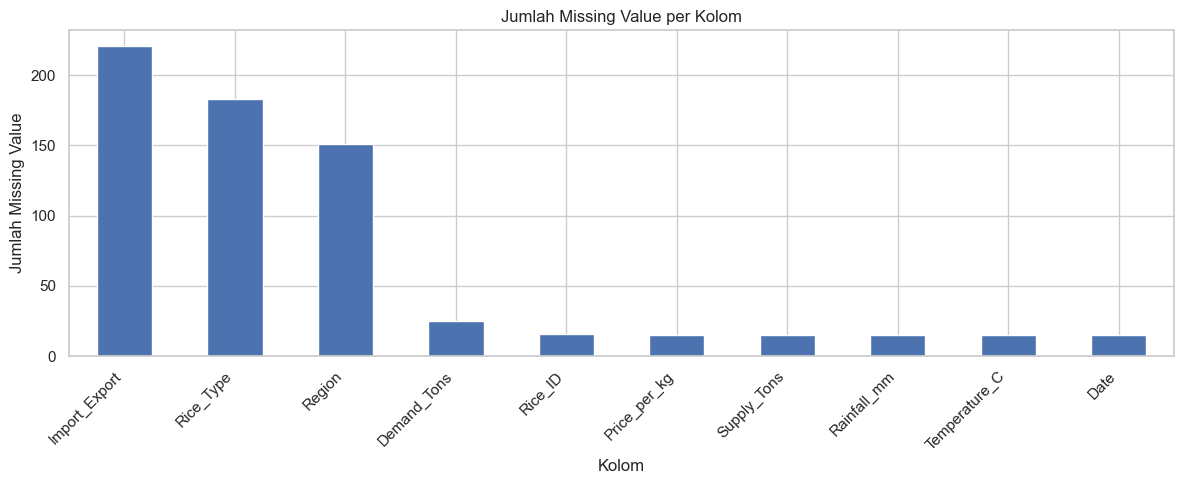

In [25]:
# Visualisasi missing value
plt.figure(figsize=(12, 5))
missing_awal[missing_awal > 0].plot(kind='bar')
plt.title('Jumlah Missing Value per Kolom')
plt.xlabel('Kolom')
plt.ylabel('Jumlah Missing Value')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

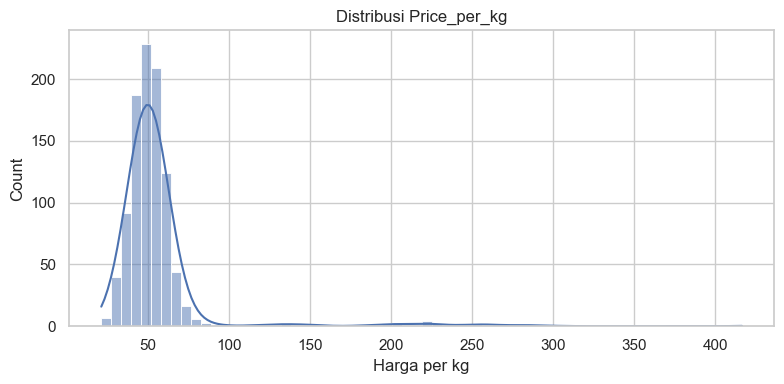

In [26]:
# Distribusi harga beras setelah dikonversi sementara ke numerik untuk visualisasi
harga_eda = pd.to_numeric(df['Price_per_kg'], errors='coerce')
plt.figure(figsize=(8, 4))
sns.histplot(harga_eda.dropna(), kde=True)
plt.title('Distribusi Price_per_kg')
plt.xlabel('Harga per kg')
plt.tight_layout()
plt.show()

## 4. Data Cleaning

Pada tahap ini, baris duplikat dihapus. `Rice_ID` diperlakukan sebagai kolom identitas sehingga tidak digunakan sebagai fitur prediksi. Kolom `Date` akan diubah menjadi fitur tahun, bulan, dan hari agar informasi waktu tetap bisa digunakan.

In [27]:
# Salin data agar data asli tetap tersedia
data = df.copy()

# Hapus baris duplikat
data = data.drop_duplicates().copy()

# Konversi target menjadi numerik; nilai yang tidak bisa dikonversi akan menjadi NaN
data['Price_per_kg'] = pd.to_numeric(data['Price_per_kg'], errors='coerce')

# Ubah Date menjadi datetime (format data contoh: DD-MM-YYYY)
data['Date'] = pd.to_datetime(data['Date'], format='%d-%m-%Y', errors='coerce')

# Ambil informasi tanggal yang dapat dipakai sebagai fitur
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Day'] = data['Date'].dt.day

# Hapus kolom identitas dan tanggal mentah
data = data.drop(columns=['Rice_ID', 'Date'], errors='ignore')

print("Ukuran data setelah duplikat dihapus:", data.shape)
display(data.head())

Ukuran data setelah duplikat dihapus: (1000, 11)


,Region,Rice_Type,Price_per_kg,Demand_Tons,Supply_Tons,Rainfall_mm,Temperature_C,Import_Export,Year,Month,Day
0,West,Jasmine,54.780900,500.409301,492.248990,167.306004,34.131247,import,2024.0,6.0,7.0
1,South,basmati,38.885870,452.714858,582.311496,281.446911,38.491452,import,2024.0,8.0,25.0
2,East,NaN,58.284545,525.206034,163.092278,176.958383,27.339138,import,NaN,NaN,NaN
3,North,Brown,49.746110,431.604050,729.691908,225.343873,15.852756,NaN,2023.0,2.0,1.0
4,West,Jasmine,40.236247,536.144204,411.336712,185.762069,31.049578,import,2024.0,9.0,8.0


## 5. Menyiapkan Target dan Data Splitting

Target prediksi adalah `Price_per_kg`. Baris yang target harganya kosong dihapus karena model supervised learning membutuhkan nilai target yang diketahui. Ini berbeda dari missing value pada fitur, yang akan diisi setelah splitting.

In [28]:
# Baris dengan target kosong tidak bisa dipakai untuk melatih atau menguji model
data_model = data.dropna(subset=['Price_per_kg']).copy()

X = data_model.drop(columns=['Price_per_kg'])
y = data_model['Price_per_kg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])
print("Jumlah fitur        :", X_train.shape[1])

Jumlah data training: 780
Jumlah data testing : 195
Jumlah fitur        : 10


## 6. Pemeriksaan dan Penanganan Outlier

Batas outlier dihitung dari data training saja. Untuk menjaga data testing tetap menjadi data evaluasi yang tidak diubah berdasarkan hasilnya, baris target outlier hanya dikeluarkan dari training. Untuk fitur numerik, nilai ekstrem akan dibatasi (capping) menggunakan batas IQR dari training, lalu batas yang sama diterapkan ke training dan testing.

In [29]:
# Tentukan fitur numerik dan kategorikal dari X_train
numeric_cols = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=['number']).columns.tolist()

# Deteksi outlier target pada data training dengan metode IQR
q1 = y_train.quantile(0.25)
q3 = y_train.quantile(0.75)
iqr = q3 - q1
lower_y = q1 - 1.5 * iqr
upper_y = q3 + 1.5 * iqr

mask_target = y_train.between(lower_y, upper_y)
print("Batas bawah target:", lower_y)
print("Batas atas target :", upper_y)
print("Target outlier yang dikeluarkan dari training:", int((~mask_target).sum()))

X_train = X_train.loc[mask_target].copy()
y_train = y_train.loc[mask_target].copy()

# Hitung batas IQR fitur numerik dari training, setelah target outlier ditangani
outlier_bounds = {}
for col in numeric_cols:
    q1_col = X_train[col].quantile(0.25)
    q3_col = X_train[col].quantile(0.75)
    iqr_col = q3_col - q1_col
    outlier_bounds[col] = (
        q1_col - 1.5 * iqr_col,
        q3_col + 1.5 * iqr_col
    )

# Terapkan batas yang berasal dari training ke data training dan testing
for col, (low, high) in outlier_bounds.items():
    X_train[col] = X_train[col].clip(lower=low, upper=high)
    X_test[col] = X_test[col].clip(lower=low, upper=high)

print("Penanganan outlier fitur numerik selesai.")

Batas bawah target: 21.36399467500001
Batas atas target : 79.53819469499999
Target outlier yang dikeluarkan dari training: 34
Penanganan outlier fitur numerik selesai.


## 7. Missing Value, Encoding, dan Standardisasi

Preprocessing dibuat menggunakan `Pipeline` dan `ColumnTransformer`. Kolom numerik diisi dengan median lalu distandardisasi. Kolom kategori diisi dengan kategori yang paling sering muncul lalu diubah menjadi kolom numerik menggunakan One-Hot Encoding. Semua langkah belajar parameternya dari training saja.

In [30]:
# Perbarui daftar kolom berdasarkan X_train
numeric_cols = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=['number']).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

print("Fitur numerik:", numeric_cols)
print("Fitur kategori:", categorical_cols)

Fitur numerik: ['Demand_Tons', 'Supply_Tons', 'Rainfall_mm', 'Temperature_C', 'Year', 'Month', 'Day']
Fitur kategori: ['Region', 'Rice_Type', 'Import_Export']


## 8. Modeling

Kita membandingkan tiga model regresi: Linear Regression, Decision Tree Regressor, dan Random Forest Regressor. Masing-masing model menggunakan preprocessing yang sama.

In [31]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42, max_depth=8),
    'Random Forest': RandomForestRegressor(
        n_estimators=200, random_state=42, max_depth=None, n_jobs=-1
    )
}

fitted_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    fitted_models[name] = pipeline
    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results).sort_values('RMSE')
display(results_df)

,Model,MAE,RMSE,R2
0,Linear Regression,14.728608,35.784429,-0.062759
2,Random Forest,14.886333,35.989960,-0.075002
1,Decision Tree,16.714255,36.981079,-0.135026


## 9. Evaluasi Model Terbaik

In [32]:
best_model_name = results_df.iloc[0]['Model']
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Model terbaik berdasarkan RMSE:", best_model_name)
print("MAE :", round(mean_absolute_error(y_test, best_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 3))
print("R2  :", round(r2_score(y_test, best_predictions), 3))

Model terbaik berdasarkan RMSE: Linear Regression
MAE : 14.729
RMSE: 35.784
R2  : -0.063


,Harga Aktual,Harga Prediksi
0,57.326494,49.596029
1,47.495320,51.498359
2,57.609047,49.345446
3,60.624015,52.124528
4,64.571958,50.670314
5,40.556312,51.122307
6,40.743792,49.980358
7,42.283717,49.475704
8,44.166420,50.247637
9,55.212953,53.486131


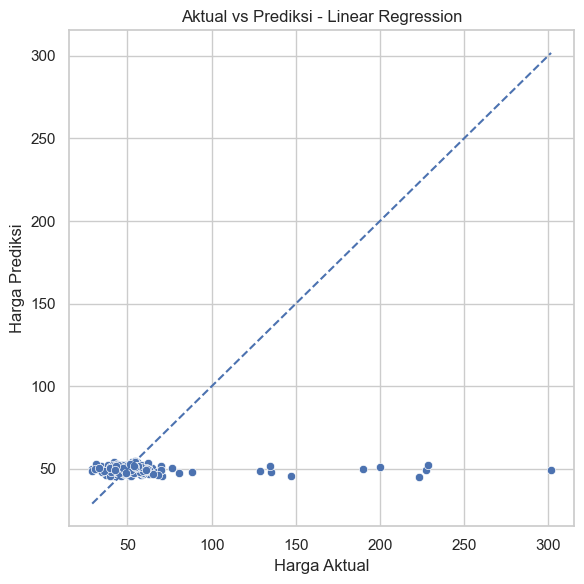

In [33]:
# Membandingkan nilai aktual dan prediksi
comparison = pd.DataFrame({
    'Harga Aktual': y_test,
    'Harga Prediksi': best_predictions
}).reset_index(drop=True)

display(comparison.head(10))

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=best_predictions)
min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')
plt.title(f'Aktual vs Prediksi - {best_model_name}')
plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.tight_layout()
plt.show()

## 10. Kesimpulan Otomatis

In [34]:
best_row = results_df.iloc[0]
print(f"Model dengan RMSE terendah adalah {best_row['Model']}.")
print(f"MAE  = {best_row['MAE']:.3f}")
print(f"RMSE = {best_row['RMSE']:.3f}")
print(f"R2   = {best_row['R2']:.3f}")
print("\nGunakan nilai metrik di atas untuk menjelaskan performa model pada laporan.")
print("RMSE dan MAE yang lebih kecil umumnya menunjukkan prediksi yang lebih dekat dengan nilai aktual.")
print("R2 yang lebih tinggi umumnya menunjukkan model menjelaskan variasi target dengan lebih baik.")

Model dengan RMSE terendah adalah Linear Regression.
MAE  = 14.729
RMSE = 35.784
R2   = -0.063

Gunakan nilai metrik di atas untuk menjelaskan performa model pada laporan.
RMSE dan MAE yang lebih kecil umumnya menunjukkan prediksi yang lebih dekat dengan nilai aktual.
R2 yang lebih tinggi umumnya menunjukkan model menjelaskan variasi target dengan lebih baik.


## Catatan untuk Laporan

- **EDA:** tulis jumlah baris/kolom, tipe data, missing value, duplikat, dan pola distribusi harga.
- **Data cleaning:** jelaskan penghapusan duplikat, konversi `Price_per_kg`, pembuatan fitur dari tanggal, serta penghapusan `Rice_ID`.
- **Data splitting:** jelaskan pembagian 80% training dan 20% testing.
- **Preprocessing:** jelaskan imputasi median/modus, One-Hot Encoding, capping outlier, dan StandardScaler.
- **Modeling dan evaluasi:** gunakan tabel metrik hasil notebook. Jangan menuliskan nilai evaluasi sebelum notebook dijalankan karena hasilnya dihitung dari dataset aktual.

## 11. Deployment: Menyimpan Model untuk API Flask

Pada materi Notion, model disimpan lalu dimuat kembali untuk diintegrasikan ke API menggunakan Flask. Pada project ini, kita menyimpan pipeline model terbaik ke file `rice_price_model.joblib`. Pipeline mencakup preprocessing dan model regresi. Batas outlier fitur dari data training juga disimpan agar input API dapat diproses dengan cara yang konsisten.

In [35]:
import joblib
import json
from pathlib import Path

# Simpan pipeline model terbaik beserta informasi fitur dan batas outlier
artifact = {
    'model': best_model,
    'feature_columns': X_train.columns.tolist(),
    'outlier_bounds': outlier_bounds,
    'numeric_columns': numeric_cols
}
joblib.dump(artifact, 'rice_price_model.joblib')

# Simpan daftar fitur agar format input API mudah diperiksa
with open('rice_price_features.json', 'w', encoding='utf-8') as f:
    json.dump(X_train.columns.tolist(), f, indent=2)

print('Model berhasil disimpan: rice_price_model.joblib')
print('Fitur API:', X_train.columns.tolist())


Model berhasil disimpan: rice_price_model.joblib
Fitur API: ['Region', 'Rice_Type', 'Demand_Tons', 'Supply_Tons', 'Rainfall_mm', 'Temperature_C', 'Import_Export', 'Year', 'Month', 'Day']


## 12. Monitoring Sederhana Model

Sesuai materi, monitoring dapat memperhatikan MSE dan R-squared untuk regresi, perubahan data input (*data drift*), serta waktu respons (*latency*). Bagian berikut mengukur waktu prediksi model terbaik pada data testing dan menampilkan metrik evaluasi. Monitoring pada notebook ini merupakan pemeriksaan lokal, belum menggunakan dashboard Prometheus/Grafana atau layanan monitoring produksi.

In [36]:
import time

start_time = time.perf_counter()
monitor_predictions = best_model.predict(X_test)
latency_total = time.perf_counter() - start_time
latency_per_row_ms = (latency_total / len(X_test)) * 1000 if len(X_test) else 0

monitor_mse = mean_squared_error(y_test, monitor_predictions)
monitor_r2 = r2_score(y_test, monitor_predictions)

monitoring_summary = pd.DataFrame([{
    'Jumlah data diuji': len(X_test),
    'MSE': monitor_mse,
    'R-squared': monitor_r2,
    'Total waktu prediksi (detik)': latency_total,
    'Rata-rata latency per data (ms)': latency_per_row_ms
}])
display(monitoring_summary)

print('Catatan: MSE dan R-squared dihitung karena nilai aktual tersedia pada data testing.')
print('Pada API, nilai aktual biasanya tidak tersedia langsung; metrik ini perlu dihitung saat nilai aktual sudah diketahui.')


,Jumlah data diuji,MSE,R-squared,Total waktu prediksi (detik),Rata-rata latency per data (ms)
0,195,1280.525359,-0.062759,0.00534,0.027387


Catatan: MSE dan R-squared dihitung karena nilai aktual tersedia pada data testing.
Pada API, nilai aktual biasanya tidak tersedia langsung; metrik ini perlu dihitung saat nilai aktual sudah diketahui.


## 13. Menjalankan API Deployment

1. Jalankan seluruh cell notebook dari atas sampai bagian Deployment agar file `rice_price_model.joblib` terbentuk.
2. Simpan file `app.py` dan `data.json` dari paket deployment di folder yang sama dengan file model tersebut.
3. Instal dependensi menggunakan `pip install -r requirements.txt`.
4. Jalankan API dengan `python app.py`.
5. Di terminal lain, uji API menggunakan `curl -X POST http://127.0.0.1:5000/predict -H "Content-Type: application/json" -d @data.json`.
6. Buka `http://127.0.0.1:5000/monitoring` untuk melihat jumlah permintaan, latency, serta MSE dan R-squared jika permintaan menyertakan nilai aktual.

API lokal ini merupakan implementasi praktikum. Untuk deployment produksi, perlu tambahan keamanan, validasi input lebih lengkap, pencatatan yang persisten, dan monitoring data drift yang lebih menyeluruh.

In [39]:
pip install -r requirements.txt


   ---------------------------------------- 0/5 [werkzeug]
   ---------------- ----------------------- 2/5 [click]
   -------------------------------- ------- 4/5 [Flask]
   ---------------------------------------- 5/5 [Flask]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\azmig\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [40]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\azmig\OneDrive\Dokumen\Jupyter\Data Mining\Kuliah\Machine Learning Praktek
['.ipynb_checkpoints', 'app.py', 'data.json', 'Dataset-Rice-C.ipynb', 'Dataset-Rice-G.ipynb', 'Hasil_Dataset_Rice_C.ipynb', 'Praktikum_Analisis_Harga_Beras_Deployment.ipynb', 'requirements.txt', 'rice_price_dataset_dirty.csv', 'rice_price_features.json', 'rice_price_model.joblib']
